# Modul 4: Regularisasi dan Hyperparameter Tuning

**Nama:** ISI NAMA  
**NIM:** ISI NIM  
**ISI KELAS  
**Tanggal:** YYYY-MM-DD  

Simpan berkas ini sebagai `M04_NIM.ipynb` sebelum mulai mengerjakan.

## Petunjuk

Notebook ini memiliki tiga jenis bagian. Tanda di akhir judul menunjukkan jenisnya.

| Tanda | Bagian | Yang Anda lakukan |
|:---|:---|:---|
| **Terbimbing** | Pre-lab A, B–F | Jawaban lengkap Prosedur Praktikum Terbimbing sudah tersedia. Jalankan, baca kodenya, lalu cocokkan keluarannya dengan tab **Materi** modul. |
| **Latihan Mandiri di Lab** | Latihan | Dikerjakan sendiri di laboratorium setelah bagian terbimbing. |
| **Tugas Individu** | Pembacaan hasil, confusion matrix, metrics, dan G | Dikerjakan di luar sesi dan dikumpulkan lewat Tugas. |

1. Pastikan Fashion-MNIST sudah ada di `data/raw` lewat tombol **Siapkan dataset di laptop** di halaman modul. Isi identitas di atas dan `NIM` pada sel pertama. Hanya itu isian pada bagian terbimbing.
2. Tekan **Restart**, lalu **Run all**. Seluruh sel terbimbing berjalan di kernel Deep Learning (PyTorch CPU) dan berhenti di sel Latihan pertama yang masih berisi `TODO`. Bagian D–F melatih 17 model; log trial tampil bertahap.
3. Keluaran yang tidak bergantung pada NIM, misalnya jumlah parameter baseline dan ukuran ruang pencarian, harus sama persis dengan naskah. Split data, seed pencarian, dan seluruh angka hasil training bergantung pada NIM Anda.
4. Pada bagian Latihan dan Tugas, ganti seluruh penanda `TODO` dan jangan mengubah protokol eksperimen kecuali diminta. Setiap run hanya mengubah satu faktor dari baseline.
5. Gunakan validation set untuk setiap keputusan. `ds_uji` baru dibuat di bagian F dan dievaluasi satu kali; jangan mengevaluasinya lagi di bagian Tugas.
6. Sebelum mengumpulkan, jalankan **Restart** lalu **Run all** sampai seluruh sel selesai tanpa galat. Pertahankan seluruh run dan trial, termasuk yang buruk atau tidak sesuai hipotesis.

In [2]:
import copy
import itertools
import platform
import random
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import transforms
from torchvision.datasets import FashionMNIST

# Kernel Workbench menangkap figure di akhir setiap sel; plt.show() dipertahankan
# agar notebook tetap berjalan di Jupyter biasa, tanpa peringatan backend Agg.
warnings.filterwarnings('ignore', message='FigureCanvasAgg is non-interactive')

NIM = '123450121'  # Ganti dengan NIM lengkap Anda, misalnya '120140167'.
assert NIM.isdigit() and len(NIM) >= 4, 'Isi NIM dengan angka sebelum melanjutkan.'
SEED = int(str(NIM)[-4:]) if str(NIM).isdigit() else 42   # seed data dan init
SEED_CARI = SEED + 1             # seed pengambilan sampel random search
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
pd.set_option('display.precision', 4)
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
print({'torch': torch.__version__, 'device': str(DEVICE),
       'seed': SEED, 'seed_cari': SEED_CARI})

{'torch': '2.14.0+cpu', 'device': 'cpu', 'seed': 121, 'seed_cari': 122}


## A. Pre-lab dan protokol anti-kebocoran · Terbimbing

1. **Overfitting vs underfitting dari kurva:** Overfitting terlihat ketika train loss terus turun/train accuracy naik, tetapi validation loss berhenti membaik lalu naik sehingga generalization gap melebar. Underfitting terlihat ketika train dan validation sama-sama buruk dan biasanya berdekatan karena model belum mampu mempelajari pola training.
2. **Mengapa dropout dimatikan saat evaluasi:** Evaluasi harus deterministik dan memakai ekspektasi seluruh unit, bukan sampel mask acak. Perintah `model.eval()` menonaktifkan perilaku stokastik `nn.Dropout`; `model.train()` mengaktifkannya kembali saat training.
3. **Weight decay pada objektif:** Ia menambahkan penalti ukuran bobot, lazimnya $\lambda\lVert\theta\rVert_2^2/2$ (konstanta bergantung konvensi), sehingga gradien mendapat komponen yang menarik bobot ke nol.
4. **Mengapa memilih dengan test membuat angka test tidak sah:** Setiap keputusan yang melihat test mentransfer informasi test ke model. Akibat seleksi berulang, test tidak lagi menjadi estimasi generalisasi yang independen dan angkanya cenderung optimistis.

### Protokol anti-kebocoran

Test set hanya boleh dipakai **setelah** arsitektur, regularisasi, learning rate, serta aturan early stopping dipilih berdasarkan validation loss. Notebook sengaja belum membuat `ds_uji` pada bagian data; konfigurasi final disalin dari baris terbaik random search, dikunci, dilatih ulang, lalu test dilewati tepat satu kali untuk menghasilkan loss, prediksi, dan confusion matrix. Angka test tidak dipakai untuk mengubah keputusan apa pun.

## B. Data · Terbimbing

Subset kecil di latih supaya overfitting terlihat. `ds_uji` **belum** dibuat di sini.

In [3]:
DATA_ROOT = Path('../../data/raw')
if not DATA_ROOT.exists():
    DATA_ROOT = Path('data/raw')

latih_penuh = FashionMNIST(root=DATA_ROOT, train=True, download=True,
                           transform=transforms.ToTensor())
uji_resmi = FashionMNIST(root=DATA_ROOT, train=False, download=True,
                         transform=transforms.ToTensor())

X_penuh = latih_penuh.data.float().unsqueeze(1) / 255.0
y_penuh = latih_penuh.targets

semua_indeks = np.arange(len(y_penuh))
idx_latih, idx_val = train_test_split(
    semua_indeks,
    train_size=3_000,
    test_size=3_000,
    stratify=y_penuh.numpy(),
    random_state=SEED,
)

X_latih, y_latih = X_penuh[idx_latih], y_penuh[idx_latih]
X_val, y_val = X_penuh[idx_val], y_penuh[idx_val]

MEAN = X_latih.mean()
STD = X_latih.std()
if not torch.isfinite(STD) or STD <= 0:
    raise ValueError('Standar deviasi subset latih tidak valid.')

def normalkan(tensor):
    return (tensor - MEAN) / STD

ds_latih = TensorDataset(normalkan(X_latih), y_latih)
ds_val = TensorDataset(normalkan(X_val), y_val)

print(f'latih {len(ds_latih)}  validasi {len(ds_val)}')
print(f'mean={MEAN.item():.6f}  std={STD.item():.6f}')
print('distribusi kelas latih:', torch.bincount(y_latih).tolist())
assert (len(ds_latih), len(ds_val)) == (3_000, 3_000)
assert torch.bincount(y_latih).min().item() == 300, 'subset harus terstratifikasi'
assert 'ds_uji' not in globals(), 'ds_uji tidak boleh dibuat sebelum bagian F'
print('split sesuai protokol; ds_uji sengaja belum dibuat')

latih 3000  validasi 3000
mean=0.286670  std=0.353971
distribusi kelas latih: [300, 300, 300, 300, 300, 300, 300, 300, 300, 300]
split sesuai protokol; ds_uji sengaja belum dibuat


In [4]:
BATCH, EPOCH = 128, 30

def buat_model(hidden=512, dropout=0.0):
    if not isinstance(hidden, int) or hidden <= 0:
        raise ValueError('hidden harus bilangan bulat positif.')
    if not 0.0 <= dropout < 1.0:
        raise ValueError('dropout harus berada pada rentang [0, 1).')
    seed_everything(SEED)
    layers = [nn.Flatten(), nn.Linear(28 * 28, hidden), nn.ReLU()]
    if dropout > 0:
        layers.append(nn.Dropout(dropout))
    layers.extend([nn.Linear(hidden, hidden), nn.ReLU()])
    if dropout > 0:
        layers.append(nn.Dropout(dropout))
    layers.append(nn.Linear(hidden, 10))
    return nn.Sequential(*layers).to(DEVICE)

def loader(ds, batch, acak):
    generator = torch.Generator().manual_seed(SEED)
    return DataLoader(ds, batch_size=batch, shuffle=acak,
                      generator=generator if acak else None)

@torch.no_grad()
def evaluasi(model, ds, batch=512):
    model.eval()
    criterion = nn.CrossEntropyLoss(reduction='sum')
    total_loss, correct = 0.0, 0
    for xb, yb in loader(ds, batch, False):
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        logits = model(xb)
        total_loss += criterion(logits, yb).item()
        correct += (logits.argmax(1) == yb).sum().item()
    return total_loss / len(ds), correct / len(ds)

n_param = sum(parameter.numel() for parameter in buat_model().parameters())
print('parameter baseline:', n_param)
assert n_param == 669_706, 'arsitektur baseline belum sesuai protokol'

parameter baseline: 669706


In [6]:
def jalankan(hidden=512, dropout=0.0, weight_decay=0.0, lr=1e-3,
             epoch=EPOCH, sabar=None, label='baseline'):
    model = buat_model(hidden=hidden, dropout=dropout)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    criterion = nn.CrossEntropyLoss()
    train_loader = loader(ds_latih, BATCH, True)
    history = {
        'epoch': [], 'train_loss': [], 'val_loss': [],
        'train_acc': [], 'val_acc': [], 'gap': [],
        'optimization_loss': [],
    }
    best_val_loss = float('inf')
    best_epoch = 0
    best_state = None
    epochs_without_improvement = 0
    status = 'ok'
    start = time.perf_counter()

    for epoch_index in range(1, epoch + 1):
        model.train()
        optimization_loss_sum = 0.0
        seen = 0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            if not torch.isfinite(loss):
                status = f'failed_nonfinite_epoch_{epoch_index}'
                break
            loss.backward()
            optimizer.step()
            optimization_loss_sum += loss.item() * len(xb)
            seen += len(xb)
        if seen == 0:
            break

        # Keduanya dievaluasi dalam model.eval() agar gap tidak dipengaruhi mask dropout.
        train_loss, train_acc = evaluasi(model, ds_latih)
        val_loss, val_acc = evaluasi(model, ds_val)
        history['epoch'].append(epoch_index)
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)
        history['gap'].append(val_loss - train_loss)
        history['optimization_loss'].append(optimization_loss_sum / seen)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch_index
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if status != 'ok':
            break
        if sabar is not None and epochs_without_improvement >= sabar:
            status = 'early_stopped'
            break

    runtime = time.perf_counter() - start
    if best_state is None:
        raise RuntimeError(f'Run {label} tidak menghasilkan checkpoint valid.')
    model.load_state_dict(best_state)
    restored_train_loss, restored_train_acc = evaluasi(model, ds_latih)
    restored_val_loss, restored_val_acc = evaluasi(model, ds_val)
    best_index = best_epoch - 1
    weight_norm = sum(
        parameter.detach().pow(2).sum().item()
        for parameter in model.parameters()
        if parameter.ndim > 1
    ) ** 0.5

    note = {
        'run_id': label,
        'seed': SEED,
        'seed_cari': SEED_CARI,
        'hidden': hidden,
        'dropout': dropout,
        'weight_decay': weight_decay,
        'learning_rate': lr,
        'patience': sabar,
        'parameter': sum(parameter.numel() for parameter in model.parameters()),
        'epoch_terbaik': best_epoch,
        'epoch_berhenti': len(history['epoch']),
        'train_loss': restored_train_loss,
        'train_acc': restored_train_acc,
        'val_loss': restored_val_loss,
        'val_acc': restored_val_acc,
        'gap': restored_val_loss - restored_train_loss,
        'val_loss_last': history['val_loss'][-1],
        'train_loss_last': history['train_loss'][-1],
        'gap_last': history['gap'][-1],
        'weight_norm': weight_norm,
        'runtime_s': runtime,
        'status': status,
    }
    assert abs(note['val_loss'] - history['val_loss'][best_index]) < 1e-7
    return model, history, note

## C. Baseline yang overfit · Terbimbing

Latih baseline tanpa regularisasi apa pun, lalu tampilkan empat kurva dalam satu figur.

,run_id,seed,seed_cari,hidden,dropout,weight_decay,learning_rate,patience,parameter,epoch_terbaik,epoch_berhenti,train_loss,train_acc,val_loss,val_acc,gap,val_loss_last,train_loss_last,gap_last,weight_norm,runtime_s,status
0,baseline,121,122,512,0.0,0.0,0.001,None,669706,6,30,0.2633,0.9013,0.4621,0.836,0.1989,0.7922,0.0312,0.7609,21.074,15.3072,ok


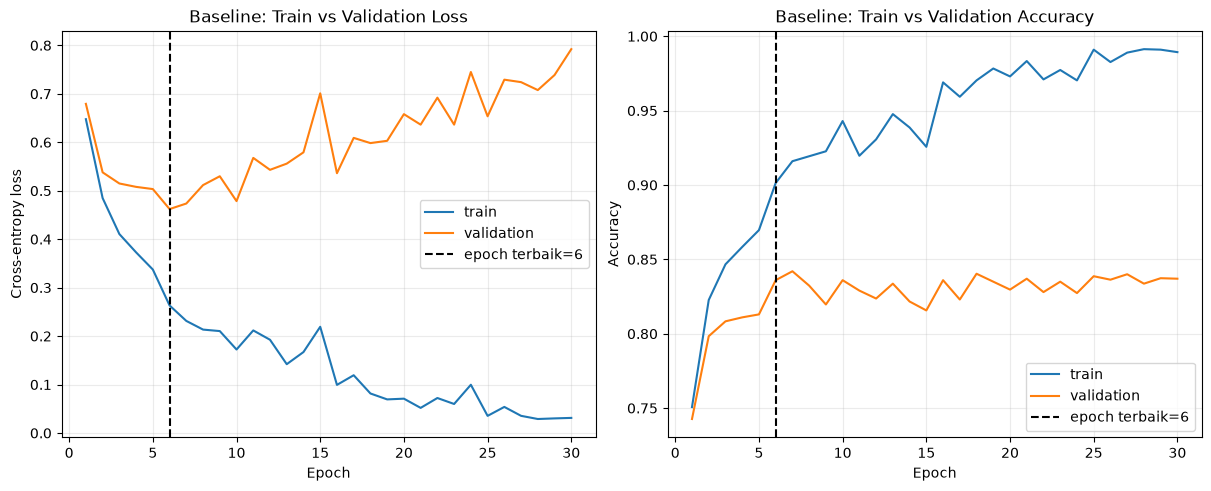

In [7]:
model_baseline, riwayat_baseline, catatan_baseline = jalankan(label='baseline')
display(pd.DataFrame([catatan_baseline]))

best_epoch_baseline = catatan_baseline['epoch_terbaik']
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)
axes[0].plot(riwayat_baseline['epoch'], riwayat_baseline['train_loss'], label='train')
axes[0].plot(riwayat_baseline['epoch'], riwayat_baseline['val_loss'], label='validation')
axes[0].axvline(best_epoch_baseline, color='black', linestyle='--',
                label=f'epoch terbaik={best_epoch_baseline}')
axes[0].set(title='Baseline: Train vs Validation Loss', xlabel='Epoch', ylabel='Cross-entropy loss')
axes[1].plot(riwayat_baseline['epoch'], riwayat_baseline['train_acc'], label='train')
axes[1].plot(riwayat_baseline['epoch'], riwayat_baseline['val_acc'], label='validation')
axes[1].axvline(best_epoch_baseline, color='black', linestyle='--',
                label=f'epoch terbaik={best_epoch_baseline}')
axes[1].set(title='Baseline: Train vs Validation Accuracy', xlabel='Epoch', ylabel='Accuracy')
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend()
plt.show()

In [8]:
baseline_evidence = f"""
**Epoch terbaik dan gap baseline:**

- Epoch dengan validation loss terendah: **{catatan_baseline['epoch_terbaik']}**.
- Validation loss pada epoch terbaik: **{catatan_baseline['val_loss']:.4f}**; pada epoch ke-{catatan_baseline['epoch_berhenti']}: **{catatan_baseline['val_loss_last']:.4f}**.
- Generalization gap pada epoch terakhir: **{catatan_baseline['gap_last']:.4f}** (`val_loss - train_loss`).
- Train loss pada epoch terbaik: **{catatan_baseline['train_loss']:.4f}**; pada epoch ke-{catatan_baseline['epoch_berhenti']}: **{catatan_baseline['train_loss_last']:.4f}**.
"""
display(Markdown(baseline_evidence))


**Epoch terbaik dan gap baseline:**

- Epoch dengan validation loss terendah: **6**.
- Validation loss pada epoch terbaik: **0.4621**; pada epoch ke-30: **0.7922**.
- Generalization gap pada epoch terakhir: **0.7609** (`val_loss - train_loss`).
- Train loss pada epoch terbaik: **0.2633**; pada epoch ke-30: **0.0312**.


## D. Tiga strategi terpisah · Terbimbing

Satu run, satu perubahan. Jangan menggabung ketiganya di tahap ini.

In [10]:
hasil = [catatan_baseline]
riwayat_strategi = {'baseline': riwayat_baseline}

strategi = [
    {'label': 'dropout_0.5', 'dropout': 0.5},
    {'label': 'weight_decay_1e-3', 'weight_decay': 1e-3},
    {'label': 'early_stopping_patience_5', 'sabar': 5},
]
for config in strategi:
    label = config.pop('label')
    _, history, note = jalankan(label=label, **config)
    hasil.append(note)
    riwayat_strategi[label] = history
    print(f"{label}: best_epoch={note['epoch_terbaik']}, val_loss={note['val_loss']:.4f}, "
          f"gap={note['gap']:.4f}, stopped={note['epoch_berhenti']}")

df_awal = pd.DataFrame(hasil)
display(df_awal[['run_id', 'epoch_terbaik', 'epoch_berhenti', 'train_loss',
                  'val_loss', 'val_acc', 'gap', 'gap_last', 'weight_norm',
                  'runtime_s', 'status']])
assert len(df_awal) == 4, 'harus ada baseline + tiga strategi'

fig, ax = plt.subplots(figsize=(8, 5))
for run_id, history in riwayat_strategi.items():
    ax.plot(history['epoch'], history['gap'], label=run_id)
ax.axhline(0, color='black', linewidth=0.8)
ax.set(title='Generalization Gap Empat Strategi', xlabel='Epoch',
       ylabel='Validation loss − train loss')
ax.grid(alpha=0.25)
ax.legend()
plt.show()

dropout_0.5: best_epoch=11, val_loss=0.4536, gap=0.1844, stopped=30


## E. Ruang pencarian dan random search · Terbimbing

Ruang berisi $3^4 = 81$ kombinasi; anggaran $12$ trial. Seed pencarian wajib dicatat agar hasil dapat diulang.

In [9]:
ruang = {
    'hidden': [64, 128, 256],
    'dropout': [0.0, 0.2, 0.5],
    'weight_decay': [0.0, 1e-4, 1e-3],
    'learning_rate': [1e-4, 3e-4, 1e-3],
}

semua_kombinasi = [
    dict(zip(ruang.keys(), values))
    for values in itertools.product(*ruang.values())
]
assert len(semua_kombinasi) == 81
rng = np.random.default_rng(SEED_CARI)
selected_indices = rng.choice(len(semua_kombinasi), size=12, replace=False)

trial = []
riwayat_trial = {}
for number, combination_index in enumerate(selected_indices, start=1):
    config = semua_kombinasi[int(combination_index)]
    run_config = config.copy()
    run_config['lr'] = run_config.pop('learning_rate')
    label = f'random_{number:02d}'
    _, history, note = jalankan(**run_config, sabar=5, label=label)
    note['combination_index'] = int(combination_index)
    trial.append(note)
    riwayat_trial[label] = history
    print(f"{label}: h={note['hidden']}, drop={note['dropout']}, wd={note['weight_decay']:g}, "
          f"lr={note['learning_rate']:g}, val_loss={note['val_loss']:.4f}")

tabel = pd.DataFrame(trial).sort_values('val_loss').reset_index(drop=True)
display(tabel[['run_id', 'hidden', 'dropout', 'weight_decay', 'learning_rate',
               'parameter', 'epoch_terbaik', 'epoch_berhenti', 'val_loss',
               'val_acc', 'gap', 'status']])
assert len(tabel) == 12, 'harus ada dua belas trial'
assert tabel['run_id'].nunique() == 12, 'run_id tiap trial harus unik'

RelayError: Sel lain masih berjalan di kernel ini. Tunggu atau hentikan dulu.

## F. Evaluasi akhir · Terbimbing

Barulah di sini `ds_uji` dibuat. Sebelum menjalankan sel ini, pastikan seluruh keputusan sudah terkunci.

In [ ]:
best_trial = tabel.iloc[0].copy()
final_config = {
    'hidden': int(best_trial['hidden']),
    'dropout': float(best_trial['dropout']),
    'weight_decay': float(best_trial['weight_decay']),
    'lr': float(best_trial['learning_rate']),
    'epoch': EPOCH,
    'sabar': 5,
    'label': 'final_retrain',
}
print('Konfigurasi ditetapkan dari validation loss:', final_config)
model_final, riwayat_final, catatan_final = jalankan(**final_config)

# Test set dan test loader baru diwujudkan setelah konfigurasi final ditetapkan dan dilatih ulang.
# Normalisasi tetap memakai MEAN dan STD subset latih.
X_uji = uji_resmi.data.float().unsqueeze(1) / 255.0
y_uji = uji_resmi.targets
ds_uji = TensorDataset(normalkan(X_uji), y_uji)
test_loader = loader(ds_uji, 512, False)

@torch.no_grad()
def evaluasi_uji_sekali(model, data_loader):
    model.eval()
    criterion = nn.CrossEntropyLoss(reduction='sum')
    total_loss = 0.0
    labels_all, predictions_all = [], []
    for xb, yb in data_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        logits = model(xb)
        total_loss += criterion(logits, yb).item()
        labels_all.append(yb.cpu())
        predictions_all.append(logits.argmax(1).cpu())
    labels = torch.cat(labels_all).numpy()
    predictions = torch.cat(predictions_all).numpy()
    return total_loss / len(data_loader.dataset), float((predictions == labels).mean()), labels, predictions

# Satu-satunya iterasi atas ds_uji.
test_loss, test_acc, test_labels, test_predictions = evaluasi_uji_sekali(model_final, test_loader)
catatan_final['test_loss'] = test_loss
catatan_final['test_acc'] = test_acc

CLASS_NAMES = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot',
]

ringkasan_akhir = pd.DataFrame([
    ('validation loss trial terpilih (bagian E)', best_trial['val_loss']),
    ('validation loss latih ulang', catatan_final['val_loss']),
    ('test loss, satu kali', test_loss),
    ('validation accuracy latih ulang', catatan_final['val_acc']),
    ('test accuracy, satu kali', test_acc),
    ('gap model final (val - train)', catatan_final['gap']),
    ('gap baseline epoch terakhir (bagian C)', catatan_baseline['gap_last']),
], columns=['besaran', 'nilai'])
print(f"trial terpilih: {best_trial['run_id']}; epoch terbaik latih ulang: {catatan_final['epoch_terbaik']}")
display(ringkasan_akhir)

## Latihan Mandiri di Lab

Bandingkan dropout 0,2 dan 0,5 pada konfigurasi baseline. Sebelum menjalankan, tuliskan prediksi Anda tentang arah perubahan train loss, validation loss, dan gap. Setelah itu jelaskan mengapa dropout yang terlalu besar dapat memperburuk kedua angka sekaligus.

Tuliskan prediksi, hasil, dan perbandingannya di `latihan-04.md`, lalu kumpulkan lewat tugas **Latihan Mandiri di Lab — Modul 04**.

**Prediksi:** TODO

In [ ]:
# TODO: latih konfigurasi baseline dengan dropout 0.2 memakai jalankan(...); faktor lain tetap
#       sama dengan baseline (hidden 512, tanpa weight decay, lr 1e-3, 30 epoch, tanpa early stopping).
# TODO: bandingkan train loss, validation loss, dan gap dengan run dropout_0.5 dari bagian D
#       (df_awal dan riwayat_strategi) serta dengan baseline.
raise NotImplementedError('Selesaikan latihan individual.')

### Hasil dan perbandingan dengan prediksi

**Jawaban:** TODO

## Pembacaan hasil, confusion matrix, dan metrics · Tugas Individu

Seluruh run yang dibaca di sini sudah tersedia dari bagian C–F. Jangan melatih ulang dan jangan mengevaluasi `ds_uji` lagi.

**Perbandingan.** Jawab dengan angka dari tabel bagian D:

- Strategi yang paling menurunkan `gap`: TODO
- Strategi yang paling menurunkan `val_loss`: TODO
- Apakah keduanya strategi yang sama? Mengapa? TODO

**Bacaan tabel.** Jawab dengan angka dari tabel random search bagian E:

- Tiga trial teratas dan jumlah parameternya: TODO
- Apakah trial dengan parameter terbanyak berada di puncak? TODO
- Hyperparameter yang tampak paling berpengaruh: TODO

In [ ]:
# Konfigurasi final, ds_uji, dan satu-satunya evaluasi test sudah tersedia dari bagian F
# (test_labels, test_predictions, CLASS_NAMES). Jangan mengevaluasi ds_uji lagi.
# TODO 9: tampilkan confusion matrix model final dan sebutkan dua kelas paling sering tertukar.
raise NotImplementedError

In [ ]:
# TODO 10: gabungkan seluruh run ke satu metrics.csv.
semua = pd.concat([df_awal, tabel], ignore_index=True)
semua.insert(0, 'module', 'M04')
semua.insert(1, 'student_id', NIM)
semua.to_csv(f'M04_{NIM}_metrics.csv', index=False)
print(f'{len(semua)} baris tersimpan')
assert len(semua) >= 16, 'metrics.csv minimal berisi 4 run awal + 12 trial'

## G. Pertanyaan analisis - bagian dari 15 poin · Tugas Individu

1. Pada epoch keberapa baseline mulai overfit, dan apa buktinya? TODO
2. Strategi mana yang paling menurunkan gap, dan mana yang paling menurunkan validation loss? TODO
3. Apakah trial dengan parameter terbanyak menghasilkan validation loss terendah? TODO
4. Hyperparameter mana yang paling berpengaruh, dan apa keterbatasan kesimpulan itu? TODO
5. Berapa selisih validation loss dan test loss model akhir, dan apa yang boleh disimpulkan darinya? TODO

**Keterbatasan.** Modul ini memakai $3\,000$ citra latih dan hanya $12$ trial dari $81$ kombinasi. Sebutkan apa yang tidak boleh disimpulkan: TODO

## Checklist sebelum mengumpulkan

- [ ] Identitas, seed data, dan seed pencarian tercantum.
- [ ] Seluruh `TODO` dan `raise NotImplementedError` sudah diganti.
- [ ] Split, stratifikasi, dan jumlah parameter lolos sel pemeriksaan.
- [ ] Baseline benar-benar memperlihatkan kenaikan validation loss.
- [ ] Tiga strategi diuji terpisah, bukan digabung.
- [ ] Dua belas trial tercatat, termasuk yang buruk.
- [ ] `ds_uji` hanya muncul pada bagian F dan dievaluasi satu kali.
- [ ] Notebook lolos *Restart Kernel and Run All*.